# Practical 3: Multiple Linear Regression (MLR) - Anti-Money Laundering
**Course**: Machine Learning (B.Tech)
**Task**: Predicting Transaction Amount Received using Multiple Financial Features

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv(r'../data/ibm_aml_transactions.csv')
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['hour'] = df['Timestamp'].dt.hour
df['dayofweek'] = df['Timestamp'].dt.dayofweek
df['is_cross_bank'] = (df['From Bank'] != df['To Bank']).astype(int)

feature_cols = ['Amount Paid', 'hour', 'dayofweek', 'is_cross_bank']
X = df[feature_cols]
y = df['Amount Received']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

mlr = LinearRegression()
mlr.fit(X_train_scaled, y_train)

print(f"Intercept: {mlr.intercept_:.4f}")
for feat, coef in zip(feature_cols, mlr.coef_):
    print(f"Coefficient ({feat}): {coef:.4f}")

y_pred = mlr.predict(X_test_scaled)
print(f"\nMAE: {mean_absolute_error(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")

Intercept: 4533330.4174
Coefficient (Amount Paid): 394983949.7899
Coefficient (hour): 70136.7644
Coefficient (dayofweek): -101834.1153
Coefficient (is_cross_bank): -463711.7007

MAE: 352520.7635
RMSE: 7577273.8317
R² Score: 0.9951


## 2. Regression Fit & Residual Analysis Visualization

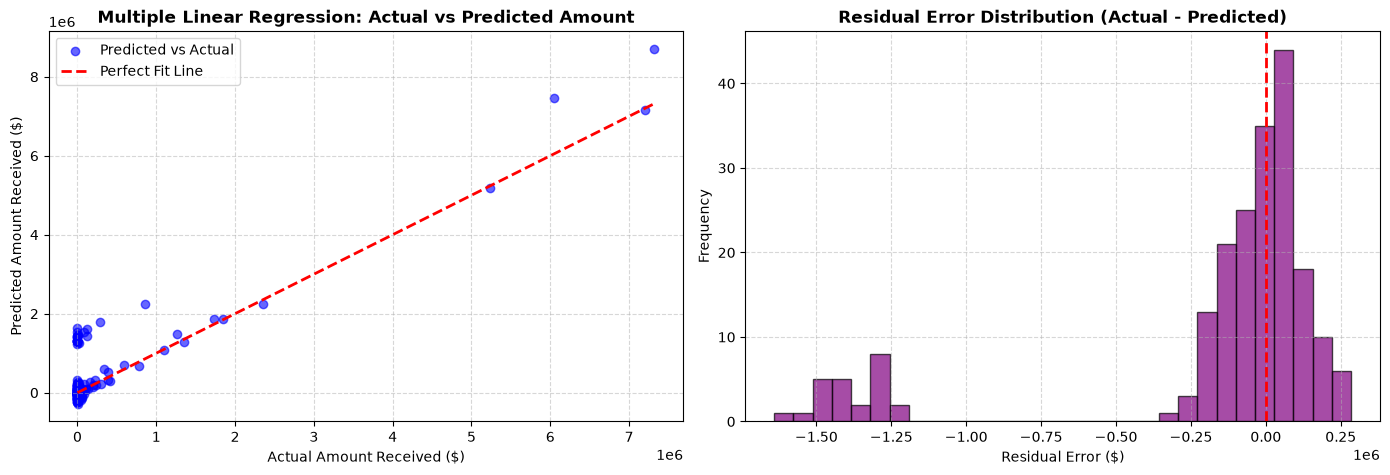

In [2]:
# Visualization: MLR Regression Fit & Residuals
import matplotlib.pyplot as plt

sample_indices = np.random.choice(len(y_test), 200, replace=False)
y_sample_true = y_test.iloc[sample_indices]
y_sample_pred = y_pred[sample_indices]
residuals = y_sample_true - y_sample_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Actual vs Predicted Scatter
axes[0].scatter(y_sample_true, y_sample_pred, color='blue', alpha=0.6, label='Predicted vs Actual')
axes[0].plot([y_sample_true.min(), y_sample_true.max()], [y_sample_true.min(), y_sample_true.max()], 'r--', linewidth=2, label='Perfect Fit Line')
axes[0].set_title('Multiple Linear Regression: Actual vs Predicted Amount', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Actual Amount Received ($)')
axes[0].set_ylabel('Predicted Amount Received ($)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Residual Distribution Plot
axes[1].hist(residuals, bins=30, color='purple', edgecolor='black', alpha=0.7)
axes[1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_title('Residual Error Distribution (Actual - Predicted)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residual Error ($)')
axes[1].set_ylabel('Frequency')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
